# Commodity Price Forecasting AI Agent
## Notebook 05 - Linear Regression Forecasting Model

### Objective

This notebook develops a Linear Regression model to predict silver closing prices using engineered historical features.

**Project:** Zetheta Project 1D

**Author:** Sanjivanee Sathe

In [7]:
# =====================================================
# Import Libraries
# =====================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries Imported Successfully")

Libraries Imported Successfully


In [8]:
# =====================================================
# Load Dataset
# =====================================================

silver = pd.read_csv(
    "../outputs/feature_engineered_silver.csv"
)

silver.head()

,Date,Open,High,Low,Close,Adj_Close,Volume,VWAP,Returns_Pct,Log_Returns,...,Open_Close_Range,EMA_7,EMA_14,EMA_30,RSI_14,MACD,MACD_Signal,BB_Middle,BB_Upper,BB_Lower
0,2000-02-14,5.3331,5.3487,5.3321,5.3336,5.3336,36878,5.3382,-0.3622,-0.003628,...,-0.0005,5.330154,5.314042,5.286113,47.688518,0.026011,0.023204,5.304540,5.417420,5.191660
1,2000-02-15,5.3607,5.3662,5.3607,5.3608,5.3608,23437,5.3626,0.5102,0.005089,...,-0.0001,5.337816,5.320276,5.290931,50.009053,0.027479,0.024059,5.306630,5.422154,5.191106
2,2000-02-16,5.3526,5.4488,5.3185,5.3539,5.3539,38455,5.3737,-0.1296,-0.001297,...,-0.0013,5.341837,5.324760,5.294994,68.792030,0.027766,0.024800,5.306575,5.422003,5.191147
3,2000-02-17,5.3307,5.4092,5.2876,5.3405,5.3405,19680,5.3458,-0.2504,-0.002507,...,-0.0098,5.341503,5.326858,5.297930,66.602363,0.026605,0.025161,5.307905,5.424297,5.191513
4,2000-02-18,5.2893,5.2949,5.2893,5.2896,5.2896,24962,5.2913,-0.9527,-0.009573,...,-0.0003,5.328527,5.321890,5.297392,58.790252,0.021332,0.024395,5.308670,5.424331,5.193009


In [9]:
# =====================================================
# Feature Selection
# =====================================================

features = [

"Open",
"High",
"Low",
"Volume",

"Lag_1",
"Lag_3",
"Lag_7",

"MA_7",
"MA_14",

"EMA_7",

"RSI_14",

"MACD"

]

X = silver[features]

y = silver["Close"]

print(X.shape)

(6753, 12)


In [10]:
# =====================================================
# Train Test Split
# =====================================================

X_train,X_test,y_train,y_test = train_test_split(

X,

y,

test_size=0.20,

shuffle=False

)

print(X_train.shape)

print(X_test.shape)

(5402, 12)
(1351, 12)


In [12]:
# =====================================================
# Linear Regression Model
# =====================================================

model = LinearRegression()

model.fit(X_train,y_train)

print("Model Trained Successfully")

Model Trained Successfully


In [13]:
# =====================================================
# Prediction
# =====================================================

predictions = model.predict(X_test)

In [14]:
# =====================================================
# Evaluation
# =====================================================

mae = mean_absolute_error(y_test,predictions)

rmse = np.sqrt(mean_squared_error(y_test,predictions))

r2 = r2_score(y_test,predictions)

print("MAE :",round(mae,4))

print("RMSE :",round(rmse,4))

print("R² :",round(r2,4))

MAE : 0.0427
RMSE : 0.0672
R² : 0.9998


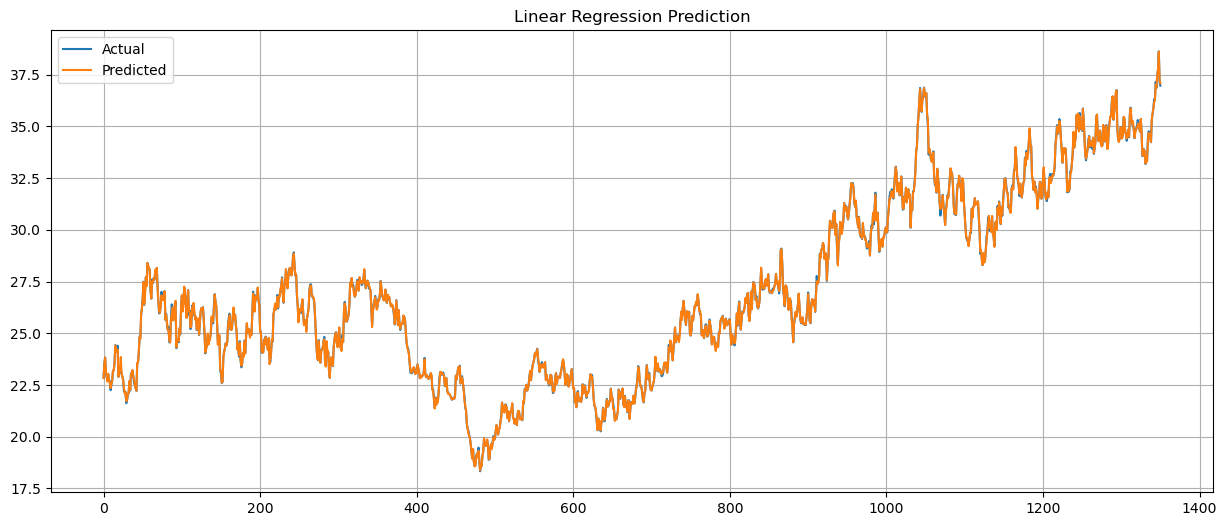

In [15]:
# =====================================================
# Actual vs Predicted
# =====================================================

plt.figure(figsize=(15,6))

plt.plot(y_test.values,label="Actual")

plt.plot(predictions,label="Predicted")

plt.title("Linear Regression Prediction")

plt.legend()

plt.grid(True)

plt.show()

In [16]:
# =====================================================
# Save Prediction
# =====================================================

results = pd.DataFrame({

"Actual":y_test,

"Predicted":predictions

})

results.to_csv(

"../outputs/linear_regression_predictions.csv",

index=False

)

print("Predictions Saved Successfully")

Predictions Saved Successfully


# Conclusion

The Linear Regression model was successfully trained using engineered features. The model predictions have been exported for comparison with ARIMA, XGBoost, LSTM, and Ensemble models.